# Student Dropout Classification - Model Training

Dataset: UCI *Predict Students' Dropout and Academic Success* (id 697).

In [39]:
from pathlib import Path

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, matthews_corrcoef, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATA_PATH = "data/students_dropout.csv"
TEST_DATA_PATH = "test_data.csv"
MODEL_DIR = Path("model")
TARGET = "Target"
RANDOM_STATE = 5326

## 1. Load data

In [26]:
df = pd.read_csv(DATA_PATH, sep=";")
# raw header has a trailing tab in 'Daytime/evening attendance'
df.columns = df.columns.str.strip()
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Exploration

In [27]:
n_rows, n_features = len(df), df.shape[1] - 1
print(f"Instances: {n_rows} (min 500)")
print(f"Features:  {n_features} (min 12)")
assert n_rows >= 500 and n_features >= 12

Instances: 4424 (min 500)
Features:  36 (min 12)


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [29]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [30]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


In [31]:
# low unique counts = integer-coded categoricals
df.drop(columns=TARGET).nunique().sort_values()

Gender                                              2
International                                       2
Scholarship holder                                  2
Tuition fees up to date                             2
Daytime/evening attendance                          2
Debtor                                              2
Educational special needs                           2
Displaced                                           2
Marital status                                      6
Application order                                   8
Inflation rate                                      9
GDP                                                10
Unemployment rate                                  10
Curricular units 2nd sem (without evaluations)     10
Curricular units 1st sem (without evaluations)     11
Previous qualification                             17
Course                                             17
Application mode                                   18
Curricular units 2nd sem (cr

## 3. Target distribution

          count  share
Target                
Graduate   2209  0.499
Dropout    1421  0.321
Enrolled    794  0.179


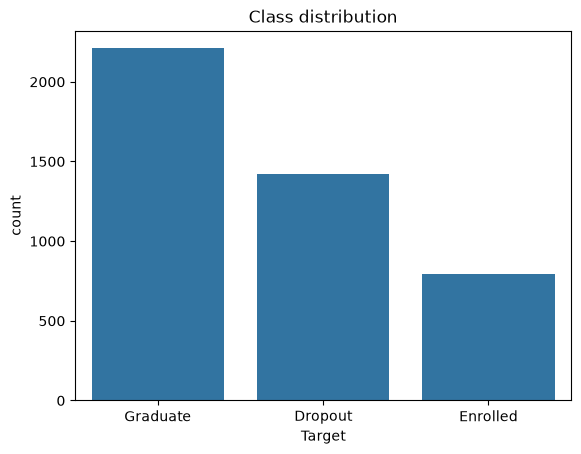

In [32]:
class_counts = df[TARGET].value_counts()
print(pd.DataFrame({"count": class_counts, "share": (class_counts / n_rows).round(3)}))

sns.countplot(data=df, x=TARGET, order=class_counts.index)
plt.title("Class distribution")
plt.show()

## 4. Preprocessing and train/test split

- Nominal integer codes (course, nationality, parents' occupation, ...) → one-hot encoded.
- All other columns → standardized.
- 80/20 stratified split; preprocessing is fit on the train set only.

In [33]:
CATEGORICAL_COLS = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]

X, y = df.drop(columns=TARGET), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)

Train: (3539, 36) | Test: (885, 36)


,train,test
Target,,
Graduate,0.499,0.499
Dropout,0.321,0.321
Enrolled,0.179,0.180


In [34]:
# rare codes grouped as 'infrequent'; unseen codes in uploaded CSVs map there too
preprocessor = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), CATEGORICAL_COLS)],
    remainder=StandardScaler(),
)
X_train_enc = preprocessor.fit_transform(X_train)
print("Raw features:", X_train.shape[1], "| Encoded features:", X_train_enc.shape[1])

Raw features: 36 | Encoded features: 131


In [35]:
# raw (unscaled) rows + target; the app's saved pipelines do the preprocessing
test_df = pd.concat([X_test, y_test], axis=1)
test_df.to_csv(TEST_DATA_PATH, index=False)
print(f"Saved {len(test_df)} rows x {test_df.shape[1]} cols -> {TEST_DATA_PATH}")

Saved 885 rows x 37 cols -> test_data.csv


## 5. Model training and evaluation

Each model is a `Pipeline(preprocessor → classifier)`: fit on the train set, scored on the held-out test set, saved to `model/`.

Multi-class metrics use **macro** averaging (each class counts equally, so weak `Enrolled` performance stays visible). AUC is one-vs-rest.

In [37]:
AVERAGE = "macro"
results = {}


def evaluate(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)
    return {
        "Accuracy": accuracy_score(y, y_pred),
        "AUC": roc_auc_score(y, y_proba, multi_class="ovr", average=AVERAGE, labels=model.classes_),
        "Precision": precision_score(y, y_pred, average=AVERAGE, zero_division=0),
        "Recall": recall_score(y, y_pred, average=AVERAGE),
        "F1": f1_score(y, y_pred, average=AVERAGE),
        "MCC": matthews_corrcoef(y, y_pred),
    }


def fit_evaluate_save(name, estimator, filename):
    model = Pipeline([("preprocess", clone(preprocessor)), ("classifier", estimator)])
    model.fit(X_train, y_train)
    results[name] = evaluate(model, X_test, y_test)
    MODEL_DIR.mkdir(exist_ok=True)
    joblib.dump(model, MODEL_DIR / filename)
    return model

### 5.1 Logistic Regression

In [38]:
lr_model = fit_evaluate_save(
    "Logistic Regression",
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "logistic_regression.pkl",
)
pd.Series(results["Logistic Regression"]).round(4)

Accuracy     0.7785
AUC          0.8979
Precision    0.7266
Recall       0.6975
F1           0.7067
MCC          0.6330
dtype: float64

### 5.2 Decision Tree

In [40]:
# depth/leaf picked by 5-fold CV on train (macro F1); unlimited depth overfit
dt_model = fit_evaluate_save(
    "Decision Tree",
    DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, random_state=RANDOM_STATE),
    "decision_tree.pkl",
)
pd.Series(results["Decision Tree"]).round(4)

Accuracy     0.7492
AUC          0.8497
Precision    0.6819
Recall       0.6564
F1           0.6622
MCC          0.5825
dtype: float64